In [1]:
import numpy as np
from astropy.constants import c, e, h, m_e
import matplotlib.pyplot as plt

c = c.cgs.value
e = e.gauss.value
h = h.cgs.value
m_e = m_e.cgs.value

/home/tomas/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


In [58]:
def PowerFunction(E_ph, E, B, pitch_angle=np.pi/2):
    """
    Compute the emitted power as a function of energy, photon energy, magnetic field, and pitch angle.
    
    Parameters:
        E_ph (float or np.ndarray): Photon energy.
        E (float or np.ndarray): Energy of the particle.
        B (float): Magnetic field strength.
        pitch_angle (float): Pitch angle (default is pi/2).
    
    Returns:
        np.ndarray: Power emitted at the given photon energy.
    """
    # Define constants
    K = np.sqrt(3) * e**3 / (h * m_e * c**2)   #En el codigo fuente de agnpy es distinto
    Ec = (3 / (4 * np.pi)) * (e * h * B * np.sin(pitch_angle))/ (m_e**3 * c**5) *np.power(E,2)
    
    #constants acording to agnpy
    #K = np.sqrt(3) * e**3 / h
    #Ec = (3 / (4 * np.pi)) * (e * h * B * np.sin(pitch_angle))/ (m_e**2 * c**3) *np.power(E,2)


    x = E_ph / Ec

    # Define an array for the Bessel integral approximation
    R = np.zeros_like(x)
    
    #(Aharonian+2010)
    R=2.15*np.power(x, 1./3.)*np.power(1.+3.06*x,1./6.)*(1.+0.884*np.power(x,2./3.)+0.471*np.power(x,4./3.))/(1+1.64*np.power(x,2./3.)+0.974*np.power(x,4./3.))*np.exp(-x)
    
    # #Function G(x), (Aharonian+2010)
    # term_1_num = 1.808 * np.power(x, 1 / 3)
    # term_1_denom = np.sqrt(1 + 3.4 * np.power(x, 2 / 3))
    # term_2_num = 1 + 2.21 * np.power(x, 2 / 3) + 0.347 * np.power(x, 4 / 3)
    # term_2_denom = 1 + 1.353 * np.power(x, 2 / 3) + 0.217 * np.power(x, 4 / 3)
    # R=term_1_num / term_1_denom * term_2_num / term_2_denom * np.exp(-x)


    # #(Finke+2008)
    
    # # Define coefficient sets for different ranges
    # coef_1 = (-0.35775237, -0.83695385, -1.1449608, -0.68137283, -0.22754737, -0.031967334)
    # coef_2 = (-0.35842494, -0.79652041, -1.6113032, 0.26055213, -1.6979017, 0.032955035)
    
    # # Apply the first set of coefficients (1e-2 < x < 1)
    # mask_1 = (x > 1e-2) & (x < 1)
    # R[mask_1] = np.exp(
    #     sum(c * x[mask_1] ** i for i, c in enumerate(coef_1))
    # )
    
    # # Apply the second set of coefficients (1 <= x < 10)
    # mask_2 = (x >= 1) & (x < 10)
    # R[mask_2] = np.exp(
    #     sum(c * x[mask_2] ** i for i, c in enumerate(coef_2))
    # )
    
    # #(Apunte de IAR)
    # R = np.power(x, 1./3.) * np.exp(-x)

    # # Compute the emitted power
    P = K * B * np.sin(pitch_angle) * R
    return P # [erg s^-1 erg^-1]


In [38]:
Emin = 2*m_e*c**2
Emax = 1e4*m_e*c**2
E = np.geomspace(Emin, Emax, 100)
p = 2.8
N = np.power(E, -p)
B = 1
E_ph = np.geomspace(1e-30, 1e-3, 150)

In [39]:
P = np.zeros((np.size(E_ph), np.size(E)))
for i, e_ in enumerate(E_ph):
    P[i] = PowerFunction(e_, E, B)

### A continuacion comparo la potencia calculada por agnpy contra la potencia calculada por el codigo anterior
# --------------------------------------------------------------------------------------------------

In [40]:
#Lo siguiente es un extracto del codigo de agnpy
def R(x):
    """Eq. 7.45 in [Dermer2009]_, angle-averaged integrand of the radiated power, the
    approximation of this function, given in Eq. D7 of [Aharonian2010]_, is used.
    """
    term_1_num = 1.808 * np.power(x, 1 / 3)
    term_1_denom = np.sqrt(1 + 3.4 * np.power(x, 2 / 3))
    term_2_num = 1 + 2.21 * np.power(x, 2 / 3) + 0.347 * np.power(x, 4 / 3)
    term_2_denom = 1 + 1.353 * np.power(x, 2 / 3) + 0.217 * np.power(x, 4 / 3)
    return term_1_num / term_1_denom * term_2_num / term_2_denom * np.exp(-x)


def calc_x(B_cgs, epsilon, gamma, mass=m_e):
    """ratio of the frequency to the critical synchrotron frequency from
    Eq. 7.34 in [DermerMenon2009]_, argument of R(x),
    note B has to be in cgs Gauss units"""
    x = (
        4
        * np.pi
        * epsilon
        * np.power(mass, 2)
        * np.power(c, 3)
        / (3 * e * B_cgs * h * np.power(gamma, 2))
    )
    return x

def single_particle_synch_power(B_cgs, epsilon, gamma, mass=m_e):
    """angle-averaged synchrotron power for a single particle of mass m_e,
    to be folded with the electron distribution
    """
    x = calc_x(B_cgs, epsilon, gamma, mass)
    prefactor = np.sqrt(3) * np.power(e, 3) * B_cgs / h
    return prefactor * R(x)


#Como dato de entrada paso los gamma asociado a la energia de e- del array que use antes
gamma=E/(m_e*c**2)

#spsp es single particle synchrotron power
spsp = np.zeros((np.size(E_ph), np.size(E)))
for i, e_ in enumerate(E_ph):
    spsp[i] = single_particle_synch_power(B, e_, gamma, m_e )


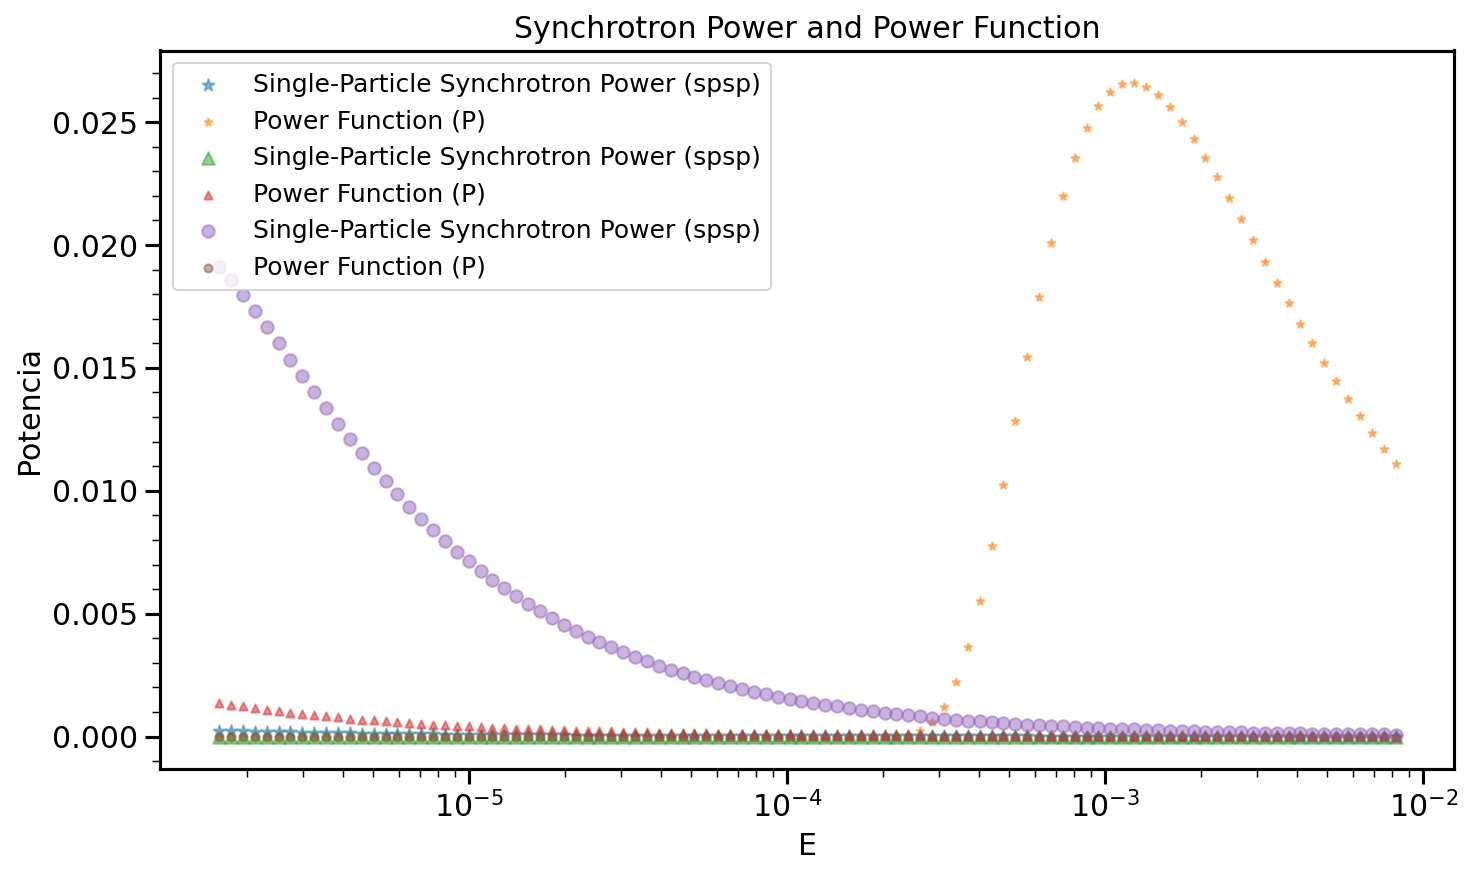

In [41]:
#Basic plotting code

# Plotting
plt.figure(figsize=(10, 6))

# Plot single-particle synchrotron power
plt.scatter(gamma*m_e*c**2, spsp[56], label="Single-Particle Synchrotron Power (spsp)", marker='*', alpha=0.5)
# Plot power function
plt.scatter(E, P[56], label="Power Function (P)", s=15, marker='*', alpha=0.5)

# Plot single-particle synchrotron power
plt.scatter(gamma*m_e*c**2, spsp[0], label="Single-Particle Synchrotron Power (spsp)", marker='^', alpha=0.5)
# Plot power function
plt.scatter(E, P[0], label="Power Function (P)", s=15, marker='^', alpha=0.5)

# Plot single-particle synchrotron power
plt.scatter(gamma*m_e*c**2, spsp[89], label="Single-Particle Synchrotron Power (spsp)", marker='o', alpha=0.5)
# Plot power function
plt.scatter(E, P[89], label="Power Function (P)", s=15, marker='o', alpha=0.5)

# Labels and title
plt.xlabel("E")
plt.ylabel("Potencia")
plt.title("Synchrotron Power and Power Function")
plt.legend()
plt.grid()
#plt.xlim(-1e-8,1e-8)
plt.xscale('log')
# Show the plot
plt.show()

# -------------------------------------------------------------------------------------------------------

In [42]:
# import numpy as np
# from scipy.constants import e, h, c, m_e

# def PowerFunctionSYNC(E_ph, E, B, pitch_angle=np.pi/2):
#     """
#     Funcion que calcula la potencia sync emitida en funcion del campo magnetico, la energia de la particula y el pitch angle
    
#     Parametros:
#         E (np.ndarray): Energia de las particulas.
#         E_ph (np.ndarray): Energia del foton emitido.
#         B (np.ndarray): Campo magnetico (a cierta altura del jet).
#         pitch_angle (float): Pitch angle.
#     """
#     # Defino la constante de la potencia
#     K = np.sqrt(3) * e**3 / (h * m_e * c**2)
    
#     # Convierto los arrays de energia y campo magnetico a matrices para poder calcular los valores  la potencia para todo E y B simultaneamente
#     E = np.atleast_1d(E)[:, np.newaxis] 
#     B = np.atleast_1d(B)[np.newaxis, :] 
    
#     # Calculo la energia caracteristica
#     Ec = (3 / (4 * np.pi)) * (e * h * B * np.sin(pitch_angle)) / (m_e**3 * c**5) * E
    
#     #Para definir la potencia emitida con cada foton construyo un arreglo tridimensional para la energia emitida 
#     E_ph = np.atleast_1d(E_ph)[:, np.newaxis, np.newaxis]  
#     x = E_ph / Ec 
    

#     R = np.zeros_like(x)


#     for i in range(x.shape[0]):
#         for j in range(x.shape[1]):
#             for k in range(x.shape[2]):
#                 if (x[i][j][k] > 1e-2) & (x[i][j][k] < 1):
#                     A0, A1, A2, A3, A4, A5 = -0.35775237, -0.83695385, -1.1449608, -0.68137283, -0.22754737, -0.031967334
#                 elif (x[i][j][k] >= 1) & (x[i][j][k] < 10):
#                     A0, A1, A2, A3, A4, A5 = -0.35842494, -0.79652041, -1.6113032, 0.26055213, -1.6979017, 0.032955035
#                 else:
#                     continue
#                 R[i][j][k] = np.exp(A0 + A1 * np.log(x[i][j][k]) + A2 * np.log(x[i][j][k])**2 +
#                       A3 * np.log(x[i][j][k])**3 + A4 * np.log(x[i][j][k])**4 + A5 * np.log(x[i][j][k])**5)
    
    
#     # Calculate emitted power
#     P = K * B * np.sin(pitch_angle) * R

    
#     return P


In [43]:
Emin = 2*m_e*c**2
Emax = 1e4*m_e*c**2
E = np.geomspace(Emin, Emax, 100)
p = 2.0
N = np.power(E, -p)
B = 100.0
E_ph = np.geomspace(1e-30, 1e-3, 150)

### Defino la emisividad

In [44]:
def q(E_ph, B, N, E):
    integ = PowerFunction(E_ph, E, B)*N
    return np.trapz(integ, E)
    # int(P(E_ph, E, B) N(E) dE)

In [45]:
q_vec = np.zeros_like(E_ph)
for i, e_ in enumerate(E_ph):
    q_vec[i] = q(e_, B, N, E)

/tmp/ipykernel_37823/1289138028.py:3: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(integ, E)


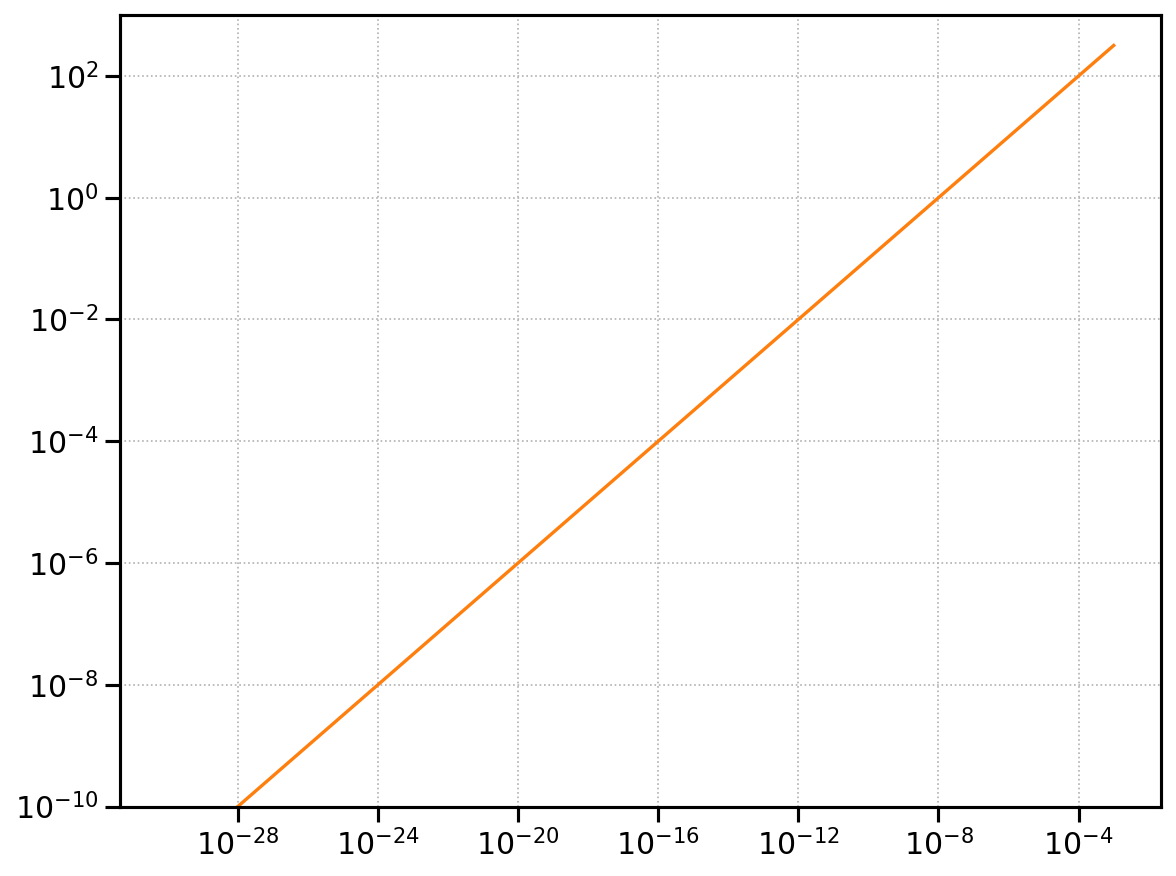

In [46]:
plt.ylim(1e-10, 1e3)
plt.loglog(E_ph, E_ph*q_vec)
plt.loglog(E_ph, 10000*np.power(E_ph, 0.5))

In [47]:
# def calcular_emisividad(P, N, E, E_ph, B):
#     """
#     Calcula una integral definida usando el método del simpson.
    
#     Parámetros:
#     - P: Potencia emitida por particula
#     - N: Numero de particulas para una dada energia
#     - E: array de energias
#     - E_ph: Energia del foton emitido
#     - B: Magnitud del campo magnetico
#     """
    
#     if len(E) % 2 != 0:
#         raise ValueError("El número de subintervalos debe ser par para la regla de Simpson.")
#     # Definimos el producto que va en la integral
#     y = P(E_ph,E,B)[0][:][0]*N
    
#     # Aplicar la regla de Simpson
#     h = (np.max(E) - np.min(E)) / (len(E))
#     integral = h / 3 * (y[0] + 4 * np.sum(y[1:len(E):2]) + 2 * np.sum(y[2:len(E)-1:2]) + y[-1])
#     return integral

# E = np.linspace(1e-3, 1e6, 3000)  # Energia de las particulas
# E_ph = np.linspace(1e-3, 1e1, 50)  # Energia de los fotones
# B = np.linspace(1e6, 6e6, 6)  # magnitud del campo magnetico

# print(B)

# N=1e5*E**-2
# j = np.empty((len(E_ph), len(B))) 
# for i, energy in enumerate(E_ph):
#     for k, magnitude in enumerate(B):
#         j[i,k]+=1/(4*np.pi)*calcular_emisividad(PowerFunctionSYNC,N,E,energy,magnitude)

# print(j.shape)



In [48]:
# import pandas as pd

# df= pd.DataFrame(j, columns=B, index=E_ph)

# df

In [49]:
# import matplotlib.pyplot as plt

# #df.drop(columns=[5000000.0], inplace=True)
# df.plot(kind='line', marker='o')
# plt.title('Grafico de emisividad a distintas frecuencias/energias en funcion del campo magnetico a altura z')
# plt.xlabel('Energia')
# plt.ylabel('Emisividad')
# plt.show

In [50]:
# pip install agnpy

In [59]:
Emin = 1e2*m_e*c**2
Emax = 1e7*m_e*c**2
E = np.geomspace(Emin, Emax, 100)
p = 2.8
N = 2e17*np.power(E, -p)
B = 1
E_ph = h*np.logspace(8,23,50)#np.geomspace(1e-30, 1e-3, 150)

q_vec = np.zeros_like(E_ph)
for i, e_ in enumerate(E_ph):
    q_vec[i] = q(e_, B, N, E)

/tmp/ipykernel_37823/1289138028.py:3: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  return np.trapz(integ, E)


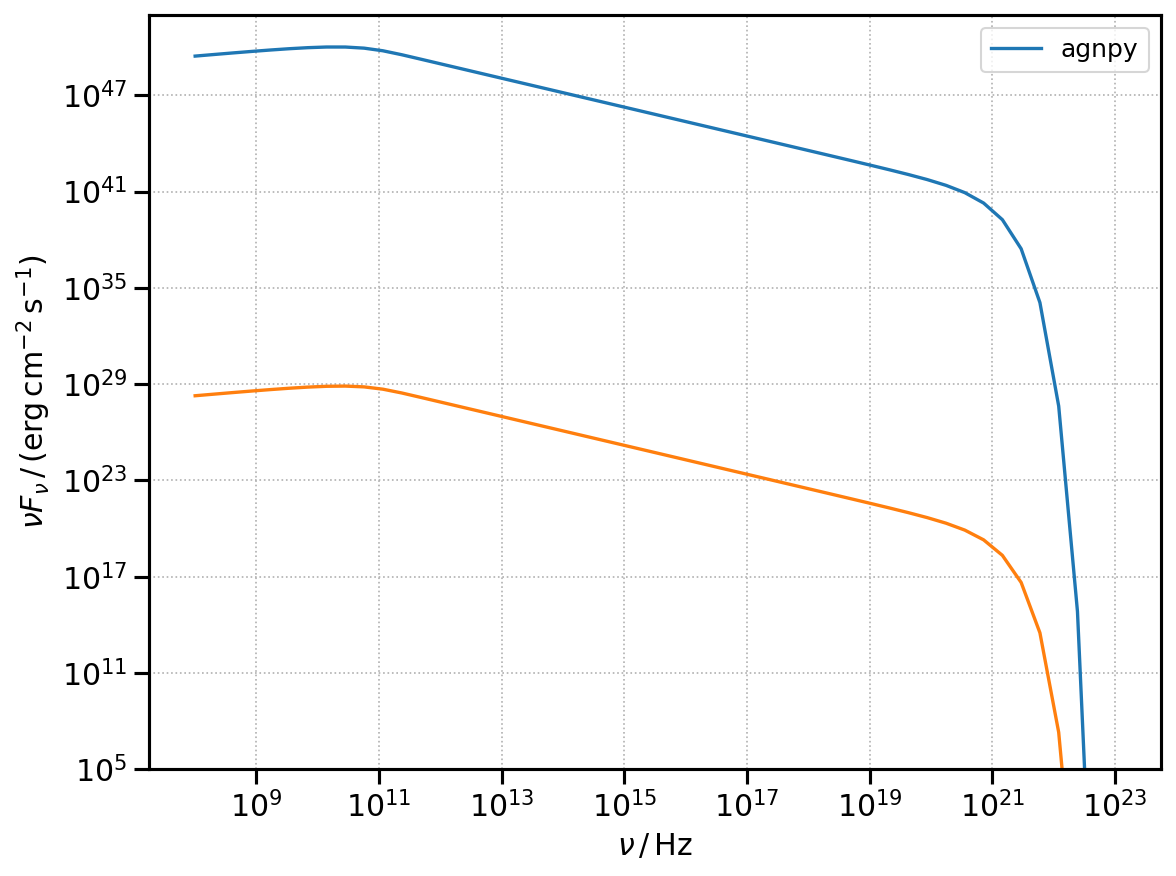

In [60]:
import numpy as np
import astropy.units as u
from astropy.constants import m_e as m_e2
from astropy.coordinates import Distance
from agnpy.spectra import PowerLaw
from agnpy.emission_regions import Blob
from agnpy.synchrotron import Synchrotron
from agnpy.utils.plot import load_mpl_rc, plot_sed
import matplotlib.pyplot as plt
from agnpy.utils.conversion import nu_to_epsilon_prime


# set the quantities defining the blob
R_b = 1e16 * u.cm
V_b = 4 / 3 * np.pi * R_b ** 3
z = Distance(1e21, unit=u.cm).z ##Menos de esta cantidad y falla
delta_D = 1
Gamma = 1
B = 1 * u.G

# electron distribution
W_e = 1e48 * u.erg#1e75 * u.erg # total energy in electrons

n_e = PowerLaw.from_total_energy(
    W_e,
    V_b,
    p=2.8,
    gamma_min=1e2,
    gamma_max=1e7,
    mass=m_e2,
)

# define the emission region and the radiative process
blob = Blob(R_b, z, delta_D, Gamma, B, n_e=n_e)
synch = Synchrotron(blob)

# compute the SED over an array of frequencies
nu = np.logspace(8, 23) * u.Hz


#Provando cosas

epsilon = nu_to_epsilon_prime(nu, z, delta_D, m = m_e2)
prefactor = np.power(delta_D, 4) / (4 * np.pi * np.power(blob.d_L, 2))
emisividad = synch.sed_flux(nu)/(epsilon*prefactor) #Multiplico por epsilon y prefactor para recuperar emisividad

# load matplotlib configuration for agnpy
load_mpl_rc() #Esta precargado, asi que cambiar los nombres de los ejes es mas trabajo. Recordar que es 


plot_sed(nu, emisividad, label="agnpy" )
plt.ylim(1e5,1e52)
plt.loglog(E_ph/h, q_vec, label='local')
plt.show()

## Notas relevantes

#### Asi se construye la sed Synchrotron
```
#conversions
        epsilon = nu_to_epsilon_prime(nu, z, delta_D, m = m_e)
        B_cgs = B_to_cgs(B)
        # reshape for multidimensional integration
        _gamma, _epsilon = axes_reshaper(gamma, epsilon)
        V_b = 4 / 3 * np.pi * np.power(R_b, 3)
        N_e = V_b * n_e.evaluate(_gamma, *args)
        # fold the electron distribution with the synchrotron power
        integrand = N_e * single_particle_synch_power(B_cgs, _epsilon, _gamma)
        emissivity = integrator(integrand, gamma, axis=0).reshape(epsilon.shape)
        prefactor = np.power(delta_D, 4) / (4 * np.pi * np.power(d_L, 2))
        sed = (prefactor * epsilon * emissivity).to("erg cm-2 s-1")
```

In [244]:
#Funcion aproximacion de la funcion G(x) del apendice D [Aharonian2010]
def R(x):
    """Eq. 7.45 in [Dermer2009]_, angle-averaged integrand of the radiated power, the
    approximation of this function, given in Eq. D7 of [Aharonian2010]_, is used.
    """
    term_1_num = 1.808 * np.power(x, 1 / 3)
    term_1_denom = np.sqrt(1 + 3.4 * np.power(x, 2 / 3))
    term_2_num = 1 + 2.21 * np.power(x, 2 / 3) + 0.347 * np.power(x, 4 / 3)
    term_2_denom = 1 + 1.353 * np.power(x, 2 / 3) + 0.217 * np.power(x, 4 / 3)
    return term_1_num / term_1_denom * term_2_num / term_2_denom * np.exp(-x)